# Stage 11 — Matched molecular pairs and activity cliffs

This stage examines structure–activity relationships in the **training/development partition only**. It finds single-cut matched molecular pairs (MMPs), identifies activity cliffs, and separately audits compounds with the same connectivity but different recorded stereochemistry. It also compares cliff and stereochemical-pair activity differences with the existing Stage 08 five-fold OOF predictions. **No model is fitted, no features are selected, and no test-set activities are read.**

## Declared activity-cliff definitions

The primary definition is **chirality-aware Morgan Tanimoto ≥ 0.90 and |ΔpIC50| ≥ 2.0** (at least a 100-fold IC50 difference). The sensitivity grid uses similarity thresholds **0.85 and 0.90** and activity gaps **1.0 and 2.0 pIC50 units**. Thresholds are inclusive and are fixed before seeing the results. Stereochemical pairs are also examined separately even when their chiral fingerprint similarity is below 0.90.

MMP transformation summaries require at least three observed pairs and at least 60% agreement in the reported direction. Depleting transformations are checked for a majority of negative changes, correcting the one-sided consistency rule in the supplied older notebook. Results are descriptive: pairs overlap in molecules and series, and assay variation can contribute to apparent cliffs.

The older Chemoinformatics notebook used a different random split and a 0.85/1.0 cliff definition. Its reported counts are not treated as results for this current scaffold-split analysis.


In [14]:
# 1. Project setup and analysis settings.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the current BRD4 QSAR project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import itertools
import math
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import rdFingerprintGenerator, rdMMPA, rdFMCS, Draw

from src.utils import OUTPUTS, load_config, stage_dir, write_manifest, setup_plotting

setup_plotting()
CFG = load_config()
SEED = int(CFG.get("seed", 42))
FP_RADIUS = int(CFG.get("fingerprint_radius", 2))
FP_SIZE = int(CFG.get("fingerprint_bits", 2048))
USE_CHIRALITY = bool(CFG.get("use_chirality", True))
SIMILARITY_THRESHOLDS = (0.85, 0.90)
ACTIVITY_GAP_THRESHOLDS = (1.0, 2.0)
PRIMARY_SIMILARITY = 0.90
PRIMARY_ACTIVITY_GAP = 2.0
MMP_MIN_PAIRS = 3
MMP_MIN_DIRECTION_CONSISTENCY = 0.60
MAX_RETAINED_SIMILAR_PAIRS = 2_000_000

STAGE_DIR = stage_dir("11_mmp_activity_cliffs")
TABLE_DIR = STAGE_DIR / "tables"
FIGURE_DIR = STAGE_DIR / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project: {PROJECT_ROOT}")
print(f"RDKit: {rdBase.rdkitVersion}")
print(f"Stage 11 outputs: {STAGE_DIR}")
print(f"Morgan settings: radius={FP_RADIUS}, bits={FP_SIZE}, chirality={USE_CHIRALITY}")
print(f"Primary cliff rule: similarity ≥ {PRIMARY_SIMILARITY:.2f} and |ΔpIC50| ≥ {PRIMARY_ACTIVITY_GAP:.1f}")


Project: c:\Users\USER\Documents\E\Code
RDKit: 2026.03.3
Stage 11 outputs: C:\Users\USER\Documents\E\Code\outputs\11_mmp_activity_cliffs
Morgan settings: radius=2, bits=2048, chirality=True
Primary cliff rule: similarity ≥ 0.90 and |ΔpIC50| ≥ 2.0


In [15]:
# 2. Load current training molecules and saved Stage 08 OOF predictions.
CLEANED_FILE = OUTPUTS / "02_clean_data/tables/cleaned_activity.csv"
TRAIN_IDS_FILE = OUTPUTS / "04_train_test_split/tables/train_ids.csv"
TEST_IDS_FILE = OUTPUTS / "04_train_test_split/tables/test_ids.csv"
TRAIN_TARGET_FILE = OUTPUTS / "05_feature_selection/tables/train_target.parquet"
OOF_FILE = OUTPUTS / "08_final_model_evaluation/tables/fresh_cv_oof_predictions_all_models.csv"
FP_FILE = OUTPUTS / "03_feature_generation/tables/ecfp4_features.parquet"
required = [CLEANED_FILE, TRAIN_IDS_FILE, TEST_IDS_FILE, TRAIN_TARGET_FILE, OOF_FILE, FP_FILE]
missing = [path for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Run Stages 02, 03, 04, 05, and 08 first. Missing files:\n"
        + "\n".join(map(str, missing))
    )

train_ids = pd.read_csv(TRAIN_IDS_FILE, dtype={"chembl_id": str})
test_ids = pd.read_csv(TEST_IDS_FILE, dtype={"chembl_id": str})
for frame in (train_ids, test_ids):
    frame["chembl_id"] = frame.chembl_id.astype(str)
if train_ids.chembl_id.duplicated().any() or test_ids.chembl_id.duplicated().any():
    raise ValueError("The Stage 04 train/test ID files contain duplicate IDs.")
train_set, test_set = set(train_ids.chembl_id), set(test_ids.chembl_id)
if train_set & test_set:
    raise ValueError("Train/test ID overlap detected; stop before Stage 11.")

# Audit partition coverage using molecule IDs only. Do not load the cleaned
# activity column or any locked-test pIC50 values.
clean_ids = pd.read_csv(CLEANED_FILE, usecols=["chembl_id"], dtype={"chembl_id": str})
clean_set = set(clean_ids.chembl_id.astype(str))
if train_set | test_set != clean_set:
    raise ValueError("Stage 04 IDs do not cover exactly the current cleaned dataset.")
del clean_ids, clean_set

# The Stage 05 target contains training rows only. Structures are loaded without
# the activity column from the cleaned table, then joined to those training IDs.
train_target = pd.read_parquet(TRAIN_TARGET_FILE)
if "pIC50" not in train_target.columns:
    raise ValueError("Stage 05 training target parquet has no pIC50 column.")
train_target.index = train_target.index.astype(str)
if train_target.index.duplicated().any() or set(train_target.index) != train_set:
    raise ValueError("Stage 05 training target IDs do not match the Stage 04 training partition.")
smiles_table = pd.read_csv(
    CLEANED_FILE, usecols=["chembl_id", "canonical_smiles"], dtype={"chembl_id": str}
)
smiles_table["chembl_id"] = smiles_table.chembl_id.astype(str)
train = train_ids[["chembl_id"]].merge(
    smiles_table, on="chembl_id", how="left", validate="one_to_one"
)
train["pIC50"] = train.chembl_id.map(train_target.pIC50)
if train[["canonical_smiles", "pIC50"]].isna().any().any():
    raise ValueError("Missing structure/activity values among training molecules.")
train["pIC50"] = pd.to_numeric(train.pIC50, errors="raise").astype(float)
if not np.isfinite(train.pIC50.to_numpy()).all():
    raise ValueError("Non-finite training pIC50 values found.")

OOF_FILE_PATH = OOF_FILE
oof = pd.read_csv(OOF_FILE, dtype={"chembl_id": str})
required_oof = {"chembl_id", "group", "fold", "model", "observed_pIC50", "predicted_pIC50"}
if not required_oof.issubset(oof.columns):
    raise ValueError(f"Stage 08 OOF file is missing columns: {sorted(required_oof - set(oof.columns))}")
oof["chembl_id"] = oof.chembl_id.astype(str)
models = sorted(oof.model.astype(str).unique())
expected_models = {"ExtraTreesRegressor", "CatBoostRegressor", "SVR"}
if set(models) != expected_models:
    raise ValueError(f"Expected Stage 08 OOF predictions for {sorted(expected_models)}; found {models}.")
for model_name, frame in oof.groupby("model"):
    if frame.chembl_id.duplicated().any() or set(frame.chembl_id) != train_set:
        raise ValueError(f"OOF molecule coverage is incomplete or duplicated for {model_name}.")
    observed = frame.set_index("chembl_id").reindex(train.chembl_id).observed_pIC50.to_numpy(float)
    if not np.allclose(observed, train.pIC50.to_numpy(float), atol=1e-10, rtol=0):
        raise ValueError(f"OOF observed activities do not match current training labels for {model_name}.")
    if set(frame.fold.astype(int)) != {1, 2, 3, 4, 5}:
        raise ValueError(f"Expected five saved OOF folds for {model_name}.")

fold_check = oof.pivot(index="chembl_id", columns="model", values="fold").reindex(train.chembl_id)
if not (fold_check.nunique(axis=1) == 1).all():
    raise ValueError("Stage 08 models do not share the same saved fold assignment per molecule.")
fold_by_id = fold_check.iloc[:, 0].astype(int).to_dict()

input_audit = pd.DataFrame([
    {"partition": "training/development", "n_molecules": len(train), "pIC50_loaded": True},
    {"partition": "locked test", "n_molecules": len(test_ids), "pIC50_loaded": False},
])
input_audit.to_csv(TABLE_DIR / "input_partition_audit.csv", index=False)
display(input_audit)
print("Training molecules, structures, and Stage 05 training-only activities are aligned.")
print("Locked-test pIC50 values were not loaded; saved Stage 08 OOF predictions are training-only.")


,partition,n_molecules,pIC50_loaded
0,training/development,5134,True
1,locked test,1283,False


Training molecules, structures, and Stage 05 training-only activities are aligned.
Locked-test pIC50 values were not loaded; saved Stage 08 OOF predictions are training-only.


In [16]:
# 3. Recreate chirality-aware Morgan fingerprints and verify against Stage 03.
MORGAN = rdFingerprintGenerator.GetMorganGenerator(
    radius=FP_RADIUS,
    fpSize=FP_SIZE,
    includeChirality=USE_CHIRALITY,
)
train["mol"] = train.canonical_smiles.map(Chem.MolFromSmiles)
if train.mol.isna().any():
    raise ValueError("Invalid canonical SMILES found in the training data.")

fp_columns = [f"ecfp4_{i}" for i in range(FP_SIZE)]
fp_table = pd.read_parquet(FP_FILE, columns=fp_columns)
fp_table.index = fp_table.index.astype(str)
if set(train.chembl_id) - set(fp_table.index):
    raise ValueError("Some training IDs are absent from the Stage 03 Morgan fingerprint table.")
fp_table = fp_table.reindex(train.chembl_id)
reference_bits = fp_table.to_numpy(dtype=np.uint8)
fp_vectors = []
computed_bits = np.zeros((len(train), FP_SIZE), dtype=np.uint8)
for row_i, mol in enumerate(tqdm(train.mol, total=len(train), desc="Rebuilding Morgan fingerprints")):
    fp = MORGAN.GetFingerprint(mol)
    fp_vectors.append(fp)
    DataStructs.ConvertToNumpyArray(fp, computed_bits[row_i])
if not np.array_equal(computed_bits, reference_bits):
    differences = int(np.count_nonzero(computed_bits != reference_bits))
    raise ValueError(
        f"Recreated Morgan bits differ from Stage 03 ({differences:,} bit cells). "
        "Check the fingerprint settings before interpreting similarity results."
    )

train["canonical_isomeric"] = [
    Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True) for mol in train.mol
]
train["canonical_nonisomeric"] = [
    Chem.MolToSmiles(mol, canonical=True, isomericSmiles=False) for mol in train.mol
]
if train.canonical_isomeric.duplicated().any():
    raise ValueError("Duplicate standardized isomeric structures remain in training data.")

fingerprint_audit = pd.DataFrame([{
    "n_training_molecules": len(train),
    "fingerprint_radius": FP_RADIUS,
    "fingerprint_bits": FP_SIZE,
    "include_chirality": USE_CHIRALITY,
    "bit_cells_matching_stage03": int(np.count_nonzero(computed_bits == reference_bits)),
    "bit_cells_compared": int(computed_bits.size),
    "exact_match": True,
}])
fingerprint_audit.to_csv(TABLE_DIR / "fingerprint_verification.csv", index=False)
display(fingerprint_audit)
print("Exact full Morgan vectors verified against Stage 03; they are not the selected 250 predictors.")


Rebuilding Morgan fingerprints:   0%|          | 0/5134 [00:00<?, ?it/s]

,n_training_molecules,fingerprint_radius,fingerprint_bits,include_chirality,bit_cells_matching_stage03,bit_cells_compared,exact_match
0,5134,2,2048,True,10514432,10514432,True


Exact full Morgan vectors verified against Stage 03; they are not the selected 250 predictors.


In [17]:
# 4. Generate RDKit MMPA fragments and diagnose every fragmentation stage.
# Preflight the installed RDKit return format before processing the full dataset.
MMPA_PATTERN = "[#6+0;!$(*=,#[!#6])]!@!=!#[*]"
MAX_CUTTABLE_BONDS_PER_MOLECULE = 30
cut_pattern = Chem.MolFromSmarts(MMPA_PATTERN)
if cut_pattern is None:
    raise RuntimeError("RDKit could not parse the declared MMPA cut pattern.")


def _as_mol(value):
    """Convert an RDKit Mol or SMILES-like fragment to a copy of a Mol."""
    if isinstance(value, Chem.Mol):
        return Chem.Mol(value)
    if isinstance(value, str) and value.strip():
        return Chem.MolFromSmiles(value)
    return None


def _canonical_fragment(mol_fragment):
    if mol_fragment is None:
        return None
    return Chem.MolToSmiles(mol_fragment, canonical=True, isomericSmiles=True)


def _parse_mmpa_record(fragment_record):
    """Return oriented (core, substituent) SMILES and a parse status.

    Some RDKit builds represent an undefined single-cut core as None; with
    resultsAsMols=False, other builds serialize that same missing core as ''.
    In both cases the second field is a dot-disconnected pair of fragments.
    """
    try:
        first_piece, second_piece = fragment_record
    except (TypeError, ValueError):
        return [], "record_not_a_pair", False

    missing_core = first_piece is None or (
        isinstance(first_piece, str) and not first_piece.strip()
    )
    if missing_core:
        combined_mol = _as_mol(second_piece)
        if combined_mol is None:
            return [], "combined_fragment_unparseable", True
        components = Chem.GetMolFrags(
            combined_mol, asMols=True, sanitizeFrags=True
        )
        if len(components) != 2:
            return [], f"expected_2_components_found_{len(components)}", True
        frag_a, frag_b = (_canonical_fragment(component) for component in components)
        if not frag_a or not frag_b:
            return [], "empty_component_smiles", True
        # Follow Notebook 8's MMP convention: the larger disconnected piece
        # is the shared core and the smaller piece is the substituent. Heavy
        # atom counts replace string character counts; canonical SMILES break
        # ties deterministically.
        paired = sorted(
            [(frag_a, components[0]), (frag_b, components[1])],
            key=lambda item: (item[1].GetNumHeavyAtoms(), item[0]),
        )
        substituent, core = paired[0][0], paired[-1][0]
        return [(core, substituent)], "two_component_record", True

    core_mol, substituent_mol = _as_mol(first_piece), _as_mol(second_piece)
    if core_mol is not None and substituent_mol is not None:
        pieces = [
            (_canonical_fragment(core_mol), core_mol),
            (_canonical_fragment(substituent_mol), substituent_mol),
        ]
        if all(smiles for smiles, _ in pieces):
            pieces.sort(key=lambda item: (item[1].GetNumHeavyAtoms(), item[0]))
            return [(pieces[-1][0], pieces[0][0])], "separate_core_and_substituent", True
    return [], "separate_fragments_unparseable", True


# Fail fast with a small diagnostic rather than spending several minutes on a
# full run if this RDKit build returns an unexpected fragment representation.
preflight_found = False
preflight_examples = []
for row in train.itertuples(index=False):
    mol = row.mol
    if mol.GetNumHeavyAtoms() < 6:
        continue
    if not mol.HasSubstructMatch(cut_pattern):
        continue
    try:
        sample_records = rdMMPA.FragmentMol(
            mol, maxCuts=1, maxCutBonds=MAX_CUTTABLE_BONDS_PER_MOLECULE,
            pattern=MMPA_PATTERN, resultsAsMols=False,
        )
    except Exception as exc:
        raise RuntimeError(
            f"MMPA preflight failed for {row.chembl_id}: {type(exc).__name__}: {exc}"
        ) from exc
    for sample_record in sample_records[:10]:
        parsed, parse_status, _ = _parse_mmpa_record(sample_record)
        if len(preflight_examples) < 3:
            preflight_examples.append({
                "record_repr": repr(sample_record)[:500],
                "parse_status": parse_status,
                "n_oriented_fragment_pairs": len(parsed),
            })
        if parsed:
            preflight_found = True
            break
    if preflight_found:
        break
if not preflight_found:
    raise RuntimeError(
        "MMPA preflight found cuttable bonds but could not interpret any returned "
        f"fragment record. Inspect these examples before running the full cell: {preflight_examples}"
    )
print("MMPA parser preflight passed:", preflight_examples)

core_members = defaultdict(lambda: defaultdict(set))
fragment_rows, diagnostic_rows = [], []
fragment_failures = 0
small_molecules_skipped = 0
for row in tqdm(train.itertuples(index=False), total=len(train), desc="Single-cut MMPA fragmentation"):
    mol = row.mol
    n_cuttable_bonds = len(mol.GetSubstructMatches(cut_pattern, uniquify=True))
    diagnostic = {
        "chembl_id": str(row.chembl_id),
        "n_heavy_atoms": int(mol.GetNumHeavyAtoms()),
        "n_cuttable_bonds": n_cuttable_bonds,
        "n_raw_fragment_records": 0,
        "n_unpacked_fragment_records": 0,
        "n_two_component_cut_records": 0,
        "n_valid_fragment_records": 0,
        "n_uninterpreted_fragment_records": 0,
        "status": "not_processed",
        "error": "",
    }
    if mol.GetNumHeavyAtoms() < 6:
        small_molecules_skipped += 1
        diagnostic["status"] = "skipped_under_6_heavy_atoms"
        diagnostic_rows.append(diagnostic)
        continue
    if n_cuttable_bonds > MAX_CUTTABLE_BONDS_PER_MOLECULE:
        diagnostic["status"] = "skipped_cut_bond_cap"
        diagnostic_rows.append(diagnostic)
        continue
    try:
        fragments = rdMMPA.FragmentMol(
            mol, maxCuts=1, maxCutBonds=MAX_CUTTABLE_BONDS_PER_MOLECULE,
            pattern=MMPA_PATTERN, resultsAsMols=False,
        )
        diagnostic["n_raw_fragment_records"] = len(fragments)
    except Exception as exc:
        fragment_failures += 1
        diagnostic["status"] = "fragmenter_exception"
        diagnostic["error"] = f"{type(exc).__name__}: {exc}"
        diagnostic_rows.append(diagnostic)
        continue

    unique_for_molecule = set()
    for fragment_record in fragments:
        parsed_pairs, parse_status, unpacked = _parse_mmpa_record(fragment_record)
        diagnostic["n_unpacked_fragment_records"] += int(unpacked)
        if parse_status == "two_component_record":
            diagnostic["n_two_component_cut_records"] += 1
        if not parsed_pairs:
            diagnostic["n_uninterpreted_fragment_records"] += 1
            if not diagnostic["error"]:
                diagnostic["error"] = parse_status
            continue
        unique_for_molecule.update(parsed_pairs)

    diagnostic["n_valid_fragment_records"] = len(unique_for_molecule)
    diagnostic["status"] = "fragments_created" if unique_for_molecule else (
        "fragment_records_not_interpreted" if diagnostic["n_raw_fragment_records"] else "no_matching_cut_bonds"
    )
    diagnostic_rows.append(diagnostic)
    for core, substituent in unique_for_molecule:
        core_members[core][str(row.chembl_id)].add(substituent)
        fragment_rows.append({"chembl_id": str(row.chembl_id), "core": core, "substituent": substituent})

fragment_diagnostics = pd.DataFrame(diagnostic_rows)
fragment_diagnostics.to_csv(TABLE_DIR / "mmp_fragmentation_diagnostics.csv", index=False)
fragment_table = pd.DataFrame(fragment_rows, columns=["chembl_id", "core", "substituent"]).drop_duplicates()
pair_rows, seen_pair_keys = [], set()
train_by_id = train.set_index("chembl_id")
for core, members in tqdm(core_members.items(), desc="Pairing shared MMP cores"):
    molecule_ids = sorted(members)
    if len(molecule_ids) < 2:
        continue
    for id_1, id_2 in itertools.combinations(molecule_ids, 2):
        for frag_1 in sorted(members[id_1]):
            for frag_2 in sorted(members[id_2]):
                if frag_1 == frag_2:
                    continue
                if frag_1 < frag_2:
                    id_from, frag_from, id_to, frag_to = id_1, frag_1, id_2, frag_2
                else:
                    id_from, frag_from, id_to, frag_to = id_2, frag_2, id_1, frag_1
                key = (core, id_from, frag_from, id_to, frag_to)
                if key in seen_pair_keys:
                    continue
                seen_pair_keys.add(key)
                y_from = float(train_by_id.at[id_from, "pIC50"])
                y_to = float(train_by_id.at[id_to, "pIC50"])
                pair_rows.append({
                    "core": core, "fragment_from": frag_from, "fragment_to": frag_to,
                    "chembl_id_from": id_from, "chembl_id_to": id_to,
                    "smiles_from": str(train_by_id.at[id_from, "canonical_smiles"]),
                    "smiles_to": str(train_by_id.at[id_to, "canonical_smiles"]),
                    "pIC50_from": y_from, "pIC50_to": y_to,
                    "delta_pIC50_to_minus_from": y_to - y_from,
                })
                if len(pair_rows) > 2_000_000:
                    raise RuntimeError("MMP pair count exceeded two million; review cut settings. No results were silently truncated.")

mmp_pair_columns = [
    "core", "fragment_from", "fragment_to", "chembl_id_from", "chembl_id_to",
    "smiles_from", "smiles_to", "pIC50_from", "pIC50_to", "delta_pIC50_to_minus_from",
]
mmp_pairs = pd.DataFrame(pair_rows, columns=mmp_pair_columns)
fragment_table.to_csv(TABLE_DIR / "mmp_fragments_training.csv", index=False)
mmp_pairs.to_csv(TABLE_DIR / "mmp_pairs_training.csv", index=False)
shared_ids = {chembl_id for ids in core_members.values() if len(ids) >= 2 for chembl_id in ids}
mmp_run_summary = pd.DataFrame([{
    "training_molecules": len(train),
    "molecules_with_fragments": fragment_table.chembl_id.nunique(),
    "unique_cores": len(core_members),
    "cores_shared_by_multiple_molecules": sum(len(v) >= 2 for v in core_members.values()),
    "unique_mmp_pairs": len(mmp_pairs),
    "fragmented_molecules_not_in_any_shared_core": len(set(fragment_table.chembl_id) - shared_ids),
    "molecules_with_no_matching_cut_bonds": int((fragment_diagnostics.status == "no_matching_cut_bonds").sum()),
    "fragmentation_failures": fragment_failures,
    "molecules_skipped_under_6_heavy_atoms": small_molecules_skipped,
    "molecules_with_uninterpreted_records": int((fragment_diagnostics.n_uninterpreted_fragment_records > 0).sum()),
    "uninterpreted_fragment_record_count": int(fragment_diagnostics.n_uninterpreted_fragment_records.sum()),
    "max_cuts": 1,
    "max_cuttable_bonds_per_molecule": MAX_CUTTABLE_BONDS_PER_MOLECULE,
    "mmpa_pattern": MMPA_PATTERN,
    "chirality_preserved_in_fragment_keys": True,
}])
mmp_run_summary.to_csv(TABLE_DIR / "mmp_run_summary.csv", index=False)
display(mmp_run_summary)
display(fragment_diagnostics.status.value_counts(dropna=False).rename_axis("fragmentation_status").to_frame("n_molecules"))
display(fragment_diagnostics.head())
display(mmp_pairs.head(10))
if mmp_pairs.empty:
    print("No exact single-cut MMPs were found. Review mmp_fragmentation_diagnostics.csv. The notebook will continue with activity cliffs, stereo pairs, and OOF analyses.")
else:
    print(f"Found {len(mmp_pairs):,} exact single-cut pairs. Positive delta means fragment_from → fragment_to raised pIC50.")


MMPA parser preflight passed: [{'record_repr': "('', 'C[*:1].Cc1nnc2ccc3c(cc([*:1])n3Cc3cccnc3)n12')", 'parse_status': 'two_component_record', 'n_oriented_fragment_pairs': 1}]


Single-cut MMPA fragmentation:   0%|          | 0/5134 [00:00<?, ?it/s]

Pairing shared MMP cores:   0%|          | 0/30111 [00:00<?, ?it/s]

,training_molecules,molecules_with_fragments,unique_cores,cores_shared_by_multiple_molecules,unique_mmp_pairs,fragmented_molecules_not_in_any_shared_core,molecules_with_no_matching_cut_bonds,fragmentation_failures,molecules_skipped_under_6_heavy_atoms,molecules_with_uninterpreted_records,uninterpreted_fragment_record_count,max_cuts,max_cuttable_bonds_per_molecule,mmpa_pattern,chirality_preserved_in_fragment_keys
0,5134,5132,30111,3513,91965,378,0,0,1,0,0,1,30,"[#6+0;!$(*=,#[!#6])]!@!=!#[*]",True


,n_molecules
fragmentation_status,
fragments_created,5132
skipped_under_6_heavy_atoms,1
skipped_cut_bond_cap,1


,chembl_id,n_heavy_atoms,n_cuttable_bonds,n_raw_fragment_records,n_unpacked_fragment_records,n_two_component_cut_records,n_valid_fragment_records,n_uninterpreted_fragment_records,status,error
0,CHEMBL5785880,21,4,4,4,4,4,0,fragments_created,
1,CHEMBL5990153,26,5,5,5,5,5,0,fragments_created,
2,CHEMBL5775485,29,7,7,7,7,7,0,fragments_created,
3,CHEMBL5843627,23,6,6,6,6,6,0,fragments_created,
4,CHEMBL5838062,25,8,7,7,7,7,0,fragments_created,


,core,fragment_from,fragment_to,chembl_id_from,chembl_id_to,smiles_from,smiles_to,pIC50_from,pIC50_to,delta_pIC50_to_minus_from
0,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,COC1CN(Cc2cccc([*:1])c2)C1,CHEMBL5750578,CHEMBL5763669,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,COC1CN(Cc2cccc(Cn3c(C)cc4c3ccc3nnc(C)n34)c2)C1,6.259637,6.259637,0.0
1,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,c1cc(CN2CCOCC2)cc([*:1])c1,CHEMBL5750578,CHEMBL5768794,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(CN2CCOCC2)c1,6.259637,6.259637,0.0
2,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CN1CCN(Cc2cccc([*:1])c2)CC1,CHEMBL5750578,CHEMBL5775485,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(CN2CCN(C)CC2)c1,6.259637,6.259637,0.0
3,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,c1cncc([*:1])c1,CHEMBL5750578,CHEMBL5785880,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccnc1,6.259637,6.259637,0.0
4,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CCNC(=O)c1cccc([*:1])c1,CHEMBL5750578,CHEMBL5818417,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,CCNC(=O)c1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,6.259637,6.259637,0.0
5,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,O[C@H]1C[C@H](NCc2cccc([*:1])c2)C1,CHEMBL5750578,CHEMBL5826838,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(CN[C@H]2C[C@H]...,6.259637,6.259637,0.0
6,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CN(C)Cc1ccc([*:1])cc1,CHEMBL5750578,CHEMBL5838062,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1ccc(CN(C)C)cc1,6.259637,6.259637,0.0
7,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,O=C(NO)c1cccc([*:1])c1,CHEMBL5750578,CHEMBL5852449,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(C(=O)NO)c1,6.259637,6.259637,0.0
8,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,N#Cc1cccc([*:1])c1,CHEMBL5750578,CHEMBL5899431,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,Cc1cc2c(ccc3nnc(C)n32)n1Cc1cccc(C#N)c1,6.259637,6.259637,0.0
9,Cc1cc2c(ccc3nnc(C)n32)n1C[*:1],CC(=O)Nc1cccc([*:1])c1,CNC(=O)c1cccc([*:1])c1,CHEMBL5750578,CHEMBL5906945,CC(=O)Nc1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,CNC(=O)c1cccc(Cn2c(C)cc3c2ccc2nnc(C)n23)c1,6.259637,6.259637,0.0


Found 91,965 exact single-cut pairs. Positive delta means fragment_from → fragment_to raised pIC50.


In [18]:
# 5. Summarize supported enriching and depleting transformations.
def summarize_transformation(group):
    delta = group.delta_pIC50_to_minus_from.astype(float)
    fraction_positive = float((delta > 0).mean())
    fraction_negative = float((delta < 0).mean())
    consistency = max(fraction_positive, fraction_negative)
    mean_delta = float(delta.mean())
    if len(delta) >= MMP_MIN_PAIRS and consistency >= MMP_MIN_DIRECTION_CONSISTENCY:
        if mean_delta > 0 and fraction_positive >= MMP_MIN_DIRECTION_CONSISTENCY:
            status = "enriching"
        elif mean_delta < 0 and fraction_negative >= MMP_MIN_DIRECTION_CONSISTENCY:
            status = "depleting"
        else:
            status = "inconsistent"
    else:
        status = "insufficient_support"
    return pd.Series({
        "n_pairs": len(delta), "n_distinct_cores": group.core.nunique(),
        "mean_delta_pIC50": mean_delta,
        "sd_delta_pIC50": float(delta.std(ddof=1)) if len(delta) > 1 else 0.0,
        "median_delta_pIC50": float(delta.median()),
        "fraction_positive": fraction_positive, "fraction_negative": fraction_negative,
        "direction_consistency": consistency, "status": status,
    })

transformation_rows = []
for (fragment_from, fragment_to), group in mmp_pairs.groupby(
    ["fragment_from", "fragment_to"], sort=False, dropna=False
):
    row = summarize_transformation(group)
    row["fragment_from"], row["fragment_to"] = fragment_from, fragment_to
    transformation_rows.append(row)
transformation_columns = [
    "fragment_from", "fragment_to", "n_pairs", "n_distinct_cores", "mean_delta_pIC50",
    "sd_delta_pIC50", "median_delta_pIC50", "fraction_positive", "fraction_negative",
    "direction_consistency", "status",
]
transformations = pd.DataFrame(transformation_rows, columns=transformation_columns).sort_values(
    ["status", "mean_delta_pIC50"], ascending=[True, False], kind="stable"
).reset_index(drop=True)
transformations.to_csv(TABLE_DIR / "mmp_transformation_summary_all.csv", index=False)
enriching = transformations.loc[transformations.status == "enriching"].sort_values(
    ["mean_delta_pIC50", "n_pairs"], ascending=[False, False], kind="stable"
)
depleting = transformations.loc[transformations.status == "depleting"].sort_values(
    ["mean_delta_pIC50", "n_pairs"], ascending=[True, False], kind="stable"
)
enriching.to_csv(TABLE_DIR / "mmp_enriching_transformations.csv", index=False)
depleting.to_csv(TABLE_DIR / "mmp_depleting_transformations.csv", index=False)
print(f"All directed fragment transformations: {len(transformations):,}")
print(f"Supported enriching transformations: {len(enriching):,}")
print(f"Supported depleting transformations: {len(depleting):,}")
if transformations.empty:
    print("No matched transformations are available; the remaining Stage 11 analyses can continue.")
display(enriching.head(15))
display(depleting.head(15))


All directed fragment transformations: 71,995
Supported enriching transformations: 1,236
Supported depleting transformations: 1,015


,fragment_from,fragment_to,n_pairs,n_distinct_cores,mean_delta_pIC50,sd_delta_pIC50,median_delta_pIC50,fraction_positive,fraction_negative,direction_consistency,status
1015,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,3,3,2.286404,0.512731,2.471047,1.0,0.0,1.0,enriching
1016,CC(C)(C)OC(=O)C[*:1],O=C(C[*:1])NCC(F)F,3,3,2.080388,2.953587,0.418570,1.0,0.0,1.0,enriching
1017,CC(C)(C)OC(=O)[*:1],O=C(NCC(F)F)[*:1],3,3,2.080388,2.953587,0.418570,1.0,0.0,1.0,enriching
1018,CC(C)(C)OC(=O)C[*:1],C[C@@H](O)CNC(=O)C[*:1],3,3,2.020592,2.991464,0.316270,1.0,0.0,1.0,enriching
1019,CC(C)(C)OC(=O)[*:1],C[C@@H](O)CNC(=O)[*:1],3,3,2.020592,2.991464,0.316270,1.0,0.0,1.0,enriching
1020,CC(C)(C)OC(=O)C[*:1],C[C@H](O)CNC(=O)C[*:1],3,3,1.924720,2.979884,0.207125,1.0,0.0,1.0,enriching
1021,CC(C)(C)OC(=O)[*:1],C[C@H](O)CNC(=O)[*:1],3,3,1.924720,2.979884,0.207125,1.0,0.0,1.0,enriching
1022,CC(C)(C)NC(=O)NCCC[*:1],CC(C)[C@H](O)C(=O)NCCC[*:1],3,3,1.086889,0.127931,1.096910,1.0,0.0,1.0,enriching
1023,CC(C)(C)NC(=O)NCCCC[*:1],CC(C)[C@H](O)C(=O)NCCCC[*:1],3,3,1.086889,0.127931,1.096910,1.0,0.0,1.0,enriching
1024,CC(C)(C)NC(=O)N[*:1],CC(C)[C@H](O)C(=O)N[*:1],3,3,1.086889,0.127931,1.096910,1.0,0.0,1.0,enriching


,fragment_from,fragment_to,n_pairs,n_distinct_cores,mean_delta_pIC50,sd_delta_pIC50,median_delta_pIC50,fraction_positive,fraction_negative,direction_consistency,status
1014,CC1C(=O)N(C)Cc2c([*:1])nc(C3CC3)n21,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,3,3,-1.664991,1.021338,-2.251638,0.000000,1.000000,1.000000,depleting
1013,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,C[C@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,5,5,-1.528331,2.079303,-2.409087,0.200000,0.800000,0.800000,depleting
1012,CC(C)(C)S(=O)(=O)N[*:1],O=S(=O)(N[*:1])c1ccccc1,3,3,-1.457994,0.647562,-1.657577,0.000000,1.000000,1.000000,depleting
1011,c1cc2cc([*:1])ccc2[nH]1,c1ccc(C[*:1])cc1,3,3,-1.314798,1.138686,-1.962929,0.000000,0.666667,0.666667,depleting
1010,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CC3)n21,C[C@H]1C(=O)N(C)Cc2c([*:1])nc(C3CC3)n21,3,3,-1.300423,2.392812,-2.656098,0.333333,0.666667,0.666667,depleting
1009,COc1cc(=O)n(C)cc1[*:1],Cn1cc([*:1])c2ccccc2c1=O,3,3,-1.292209,0.774371,-0.851869,0.000000,1.000000,1.000000,depleting
1008,CC(C)(C)N[*:1],c1ccc(CN[*:1])cc1,3,3,-1.278257,0.243938,-1.361057,0.000000,1.000000,1.000000,depleting
1006,CC(C)(C)S(=O)(=O)Nc1cc(N[*:1])ccc1Cl,Cc1ccc(N[*:1])cc1S(=O)(=O)NC1CCC1,4,4,-1.256133,0.317595,-1.255942,0.000000,1.000000,1.000000,depleting
1007,CC(C)(C)S(=O)(=O)Nc1cc([*:1])ccc1Cl,Cc1ccc([*:1])cc1S(=O)(=O)NC1CCC1,4,4,-1.256133,0.317595,-1.255942,0.000000,1.000000,1.000000,depleting
1005,CC(C)Oc1cccc([*:1])c1,c1cc2c(cc1[*:1])OCO2,3,3,-1.244515,0.903907,-1.579572,0.000000,1.000000,1.000000,depleting


In [19]:
# 6. Exact chirality-aware pairwise similarity search and cliff sensitivity.
# Similarities are calculated for every unordered training pair. Only pairs at
# the lowest declared similarity AND activity-gap thresholds are retained.
y_train = train.pIC50.to_numpy(dtype=float)
n_train = len(train)
min_similarity = min(SIMILARITY_THRESHOLDS)
min_gap = min(ACTIVITY_GAP_THRESHOLDS)
similar_pair_counts = {threshold: 0 for threshold in SIMILARITY_THRESHOLDS}
cliff_candidate_rows = []

for i in tqdm(range(n_train - 1), desc="All-pairs Morgan Tanimoto search"):
    similarities = np.asarray(
        DataStructs.BulkTanimotoSimilarity(fp_vectors[i], fp_vectors[i + 1:]),
        dtype=np.float32,
    )
    for threshold in SIMILARITY_THRESHOLDS:
        similar_pair_counts[threshold] += int(np.count_nonzero(similarities >= threshold))
    keep_similarity = np.flatnonzero(similarities >= min_similarity)
    if not len(keep_similarity):
        continue
    j_values = keep_similarity + i + 1
    deltas = y_train[j_values] - y_train[i]
    keep_gap = np.flatnonzero(np.abs(deltas) >= min_gap)
    for offset in keep_gap:
        j = int(j_values[offset])
        cliff_candidate_rows.append({
            "chembl_id_a": str(train.chembl_id.iloc[i]),
            "chembl_id_b": str(train.chembl_id.iloc[j]),
            "smiles_a": str(train.canonical_smiles.iloc[i]),
            "smiles_b": str(train.canonical_smiles.iloc[j]),
            "pIC50_a": float(y_train[i]),
            "pIC50_b": float(y_train[j]),
            "delta_pIC50_b_minus_a": float(deltas[offset]),
            "absolute_delta_pIC50": float(abs(deltas[offset])),
            "tanimoto_chiral": float(similarities[keep_similarity[offset]]),
            "fold_a": int(fold_by_id[str(train.chembl_id.iloc[i])]),
            "fold_b": int(fold_by_id[str(train.chembl_id.iloc[j])]),
            "same_evaluation_fold": bool(
                fold_by_id[str(train.chembl_id.iloc[i])] == fold_by_id[str(train.chembl_id.iloc[j])]
            ),
        })
    if len(cliff_candidate_rows) > MAX_RETAINED_SIMILAR_PAIRS:
        raise RuntimeError(
            "Retained similar/high-gap pair count exceeded the declared safety limit. "
            "No pairs were truncated; review the analysis settings before rerunning."
        )

similar_pairs = pd.DataFrame(cliff_candidate_rows)
if similar_pairs.empty:
    similar_pairs = pd.DataFrame(columns=[
        "chembl_id_a", "chembl_id_b", "smiles_a", "smiles_b", "pIC50_a", "pIC50_b",
        "delta_pIC50_b_minus_a", "absolute_delta_pIC50", "tanimoto_chiral",
        "fold_a", "fold_b", "same_evaluation_fold",
    ])
similar_pairs.to_csv(TABLE_DIR / "similar_pairs_minimum_sensitivity_thresholds.csv", index=False)

sensitivity_rows = []
for sim_threshold in SIMILARITY_THRESHOLDS:
    for gap_threshold in ACTIVITY_GAP_THRESHOLDS:
        subset = similar_pairs.loc[
            (similar_pairs.tanimoto_chiral >= sim_threshold)
            & (similar_pairs.absolute_delta_pIC50 >= gap_threshold)
        ]
        members = set(subset.chembl_id_a) | set(subset.chembl_id_b)
        sensitivity_rows.append({
            "similarity_threshold_inclusive": sim_threshold,
            "activity_gap_threshold_inclusive_pIC50": gap_threshold,
            "n_similar_pairs_at_similarity_threshold": similar_pair_counts[sim_threshold],
            "n_activity_cliffs": len(subset),
            "n_unique_cliff_molecules": len(members),
            "n_same_evaluation_fold_pairs": int(subset.same_evaluation_fold.sum()),
            "n_cross_evaluation_fold_pairs": int((~subset.same_evaluation_fold).sum()),
        })
cliff_sensitivity = pd.DataFrame(sensitivity_rows)
cliff_sensitivity.to_csv(TABLE_DIR / "activity_cliff_threshold_sensitivity.csv", index=False)
primary_cliffs = similar_pairs.loc[
    (similar_pairs.tanimoto_chiral >= PRIMARY_SIMILARITY)
    & (similar_pairs.absolute_delta_pIC50 >= PRIMARY_ACTIVITY_GAP)
].sort_values(
    ["absolute_delta_pIC50", "tanimoto_chiral"], ascending=[False, False], kind="stable"
).reset_index(drop=True)
primary_cliffs.insert(0, "cliff_rank", np.arange(1, len(primary_cliffs) + 1))
primary_cliffs.to_csv(TABLE_DIR / "primary_activity_cliffs_training.csv", index=False)

display(cliff_sensitivity)
print(f"Exact similar-pair counts at similarity ≥0.85: {similar_pair_counts[0.85]:,}")
print(f"Exact similar-pair counts at similarity ≥0.90: {similar_pair_counts[0.90]:,}")
print(f"Primary training cliffs (≥0.90, ≥2.0 pIC50): {len(primary_cliffs):,}")
display(primary_cliffs.head(15))


All-pairs Morgan Tanimoto search:   0%|          | 0/5133 [00:00<?, ?it/s]

,similarity_threshold_inclusive,activity_gap_threshold_inclusive_pIC50,n_similar_pairs_at_similarity_threshold,n_activity_cliffs,n_unique_cliff_molecules,n_same_evaluation_fold_pairs,n_cross_evaluation_fold_pairs
0,0.85,1.0,1464,154,232,96,58
1,0.85,2.0,1464,26,48,22,4
2,0.90,1.0,461,44,78,23,21
3,0.90,2.0,461,6,10,3,3


Exact similar-pair counts at similarity ≥0.85: 1,464
Exact similar-pair counts at similarity ≥0.90: 461
Primary training cliffs (≥0.90, ≥2.0 pIC50): 6


,cliff_rank,chembl_id_a,chembl_id_b,smiles_a,smiles_b,pIC50_a,pIC50_b,delta_pIC50_b_minus_a,absolute_delta_pIC50,tanimoto_chiral,fold_a,fold_b,same_evaluation_fold
0,1,CHEMBL3650963,CHEMBL3650964,Cc1nn(C2CC2)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(C)c3...,Cc1nn(C2CC2)c2c1[C@@H](c1ccc(Cl)cc1)N(c1cc(C)c...,4.522879,7.886057,3.363178,3.363178,0.964286,4,2,False
1,2,CHEMBL3650937,CHEMBL3650969,Cc1nn(-c2ccnn2C)c2c1C(c1ccc(Cl)cc1)N(c1cc(C)c3...,Cc1nn(-c2ccnn2C)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(...,7.823909,4.602060,-3.221849,3.221849,0.967213,5,3,False
2,3,CHEMBL3650963,CHEMBL3650938,Cc1nn(C2CC2)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(C)c3...,Cc1nn(C2CC2)c2c1C(c1ccc(Cl)cc1)N(c1cc(C)c3nnc(...,4.522879,7.721246,3.198368,3.198368,0.964286,4,4,True
3,4,CHEMBL3650969,CHEMBL3650970,Cc1nn(-c2ccnn2C)c2c1[C@H](c1ccc(Cl)cc1)N(c1cc(...,Cc1nn(-c2ccnn2C)c2c1[C@@H](c1ccc(Cl)cc1)N(c1cc...,4.602060,7.602060,3.000000,3.000000,0.967213,3,3,True
4,5,CHEMBL3650944,CHEMBL3650945,COc1ncc(-n2nc(C)c3c2C(=O)N(c2cc(C)c(=O)n(C)c2)...,COc1ncc(-n2nc(C)c3c2C(=O)N(c2cc(C)c(=O)n(C)c2)...,5.107905,7.602060,2.494155,2.494155,0.969231,4,4,True
5,6,CHEMBL3650973,CHEMBL3650972,COc1ncccc1-n1nc(C)c2c1C(=O)N(c1cc(C)c(=O)n(C)c...,COc1ncccc1-n1nc(C)c2c1C(=O)N(c1cc(C)c(=O)n(C)c...,7.443697,5.244125,-2.199572,2.199572,0.968254,3,1,False


In [20]:
# 7. Identify recorded stereochemical pairs and compare pair deltas with OOF predictions.
def tetrahedral_assignment_status(mol):
    centers = Chem.FindMolChiralCenters(
        mol, includeUnassigned=True, includeCIP=True, useLegacyImplementation=False
    )
    if not centers:
        return "no tetrahedral stereocenter detected"
    unknown = sum(label == "?" for _, label in centers)
    if unknown:
        return f"{unknown} unspecified tetrahedral center(s)"
    return "tetrahedral centers specified"

stereo_rows = []
for connectivity, group in train.groupby("canonical_nonisomeric", sort=False):
    if group.canonical_isomeric.nunique() < 2:
        continue
    group = group.sort_values("chembl_id", kind="stable")
    records = list(group.itertuples(index=False))
    for a, b in itertools.combinations(records, 2):
        if a.canonical_isomeric == b.canonical_isomeric:
            continue
        ia, ib = train.index[train.chembl_id.eq(str(a.chembl_id))][0], train.index[train.chembl_id.eq(str(b.chembl_id))][0]
        stereo_rows.append({
            "connectivity_key": connectivity,
            "chembl_id_a": str(a.chembl_id),
            "chembl_id_b": str(b.chembl_id),
            "smiles_a": str(a.canonical_smiles),
            "smiles_b": str(b.canonical_smiles),
            "canonical_isomeric_a": str(a.canonical_isomeric),
            "canonical_isomeric_b": str(b.canonical_isomeric),
            "stereo_status_a": tetrahedral_assignment_status(a.mol),
            "stereo_status_b": tetrahedral_assignment_status(b.mol),
            "pIC50_a": float(a.pIC50),
            "pIC50_b": float(b.pIC50),
            "delta_pIC50_b_minus_a": float(b.pIC50 - a.pIC50),
            "absolute_delta_pIC50": float(abs(b.pIC50 - a.pIC50)),
            "tanimoto_chiral": float(DataStructs.TanimotoSimilarity(fp_vectors[ia], fp_vectors[ib])),
            "fold_a": int(fold_by_id[str(a.chembl_id)]),
            "fold_b": int(fold_by_id[str(b.chembl_id)]),
            "same_evaluation_fold": bool(fold_by_id[str(a.chembl_id)] == fold_by_id[str(b.chembl_id)]),
        })

stereo_pairs = pd.DataFrame(stereo_rows)
if stereo_pairs.empty:
    stereo_pairs = pd.DataFrame(columns=[
        "connectivity_key", "chembl_id_a", "chembl_id_b", "smiles_a", "smiles_b",
        "canonical_isomeric_a", "canonical_isomeric_b", "stereo_status_a", "stereo_status_b",
        "pIC50_a", "pIC50_b", "delta_pIC50_b_minus_a", "absolute_delta_pIC50",
        "tanimoto_chiral", "fold_a", "fold_b", "same_evaluation_fold",
    ])
if len(stereo_pairs) > 100_000:
    raise RuntimeError("Recorded stereo pair count exceeded 100,000; review before continuing.")
stereo_pairs.to_csv(TABLE_DIR / "recorded_stereochemical_pairs_training.csv", index=False)
stereo_summary = pd.DataFrame([{
    "n_recorded_stereochemical_pairs": len(stereo_pairs),
    "n_pairs_with_absolute_delta_ge_1": int((stereo_pairs.absolute_delta_pIC50 >= 1.0).sum()),
    "n_pairs_with_absolute_delta_ge_2": int((stereo_pairs.absolute_delta_pIC50 >= 2.0).sum()),
    "n_pairs_with_chiral_similarity_ge_0_90": int((stereo_pairs.tanimoto_chiral >= 0.90).sum()),
    "n_pairs_below_chiral_similarity_0_90": int((stereo_pairs.tanimoto_chiral < 0.90).sum()),
}])
stereo_summary.to_csv(TABLE_DIR / "stereochemical_pair_summary.csv", index=False)


def oof_pair_comparison(pairs, pair_type):
    rows = []
    for pair in pairs.itertuples(index=False):
        actual_delta = float(pair.delta_pIC50_b_minus_a)
        for model_name, model_oof in oof.groupby("model", sort=False):
            by_id = model_oof.set_index("chembl_id")
            pred_a = float(by_id.at[str(pair.chembl_id_a), "predicted_pIC50"])
            pred_b = float(by_id.at[str(pair.chembl_id_b), "predicted_pIC50"])
            fold_a = int(by_id.at[str(pair.chembl_id_a), "fold"])
            fold_b = int(by_id.at[str(pair.chembl_id_b), "fold"])
            predicted_delta = pred_b - pred_a
            rows.append({
                "pair_type": pair_type,
                "model": model_name,
                "chembl_id_a": str(pair.chembl_id_a),
                "chembl_id_b": str(pair.chembl_id_b),
                "observed_delta_pIC50_b_minus_a": actual_delta,
                "predicted_delta_pIC50_b_minus_a": predicted_delta,
                "absolute_delta_error": abs(predicted_delta - actual_delta),
                "direction_recovered": bool(np.sign(predicted_delta) == np.sign(actual_delta)),
                "primary_gap_magnitude_recovered": bool(abs(predicted_delta) >= PRIMARY_ACTIVITY_GAP),
                "fold_a": fold_a,
                "fold_b": fold_b,
                "same_evaluation_fold": bool(fold_a == fold_b),
            })
    return pd.DataFrame(rows)

cliff_oof = oof_pair_comparison(primary_cliffs, "primary_activity_cliff")
stereo_oof = oof_pair_comparison(stereo_pairs, "recorded_stereochemical_pair")
cliff_oof.to_csv(TABLE_DIR / "primary_cliff_oof_pair_predictions.csv", index=False)
stereo_oof.to_csv(TABLE_DIR / "stereochemical_pair_oof_predictions.csv", index=False)

pair_oof_all = pd.concat([cliff_oof, stereo_oof], ignore_index=True)
if pair_oof_all.empty:
    pair_oof_metrics = pd.DataFrame(columns=[
        "pair_type", "model", "same_evaluation_fold", "n_pairs",
        "mean_absolute_delta_error", "direction_recovery_fraction",
        "primary_gap_magnitude_recovery_fraction",
    ])
else:
    pair_oof_metrics = (
        pair_oof_all.groupby(["pair_type", "model", "same_evaluation_fold"], dropna=False)
        .agg(
            n_pairs=("absolute_delta_error", "size"),
            mean_absolute_delta_error=("absolute_delta_error", "mean"),
            direction_recovery_fraction=("direction_recovered", "mean"),
            primary_gap_magnitude_recovery_fraction=("primary_gap_magnitude_recovered", "mean"),
        )
        .reset_index()
    )
pair_oof_metrics.to_csv(TABLE_DIR / "oof_pair_difference_metrics.csv", index=False)

display(stereo_summary)
display(stereo_pairs.head(15))
print("OOF pair comparison (same-fold and cross-fold pairs shown separately):")
display(pair_oof_metrics)
print("Cross-fold pair predictions combine two different fold models; they do not withhold both analogues in one model.")


,n_recorded_stereochemical_pairs,n_pairs_with_absolute_delta_ge_1,n_pairs_with_absolute_delta_ge_2,n_pairs_with_chiral_similarity_ge_0_90,n_pairs_below_chiral_similarity_0_90
0,405,55,23,170,235


,connectivity_key,chembl_id_a,chembl_id_b,smiles_a,smiles_b,canonical_isomeric_a,canonical_isomeric_b,stereo_status_a,stereo_status_b,pIC50_a,pIC50_b,delta_pIC50_b_minus_a,absolute_delta_pIC50,tanimoto_chiral,fold_a,fold_b,same_evaluation_fold
0,Cc1nnc2c(NCCCCNC(=O)C(O)C(C)C)nc3cc(F)c(F)cc3n12,CHEMBL5748230,CHEMBL6058883,Cc1nnc2c(NCCCCNC(=O)[C@@H](O)C(C)C)nc3cc(F)c(F...,Cc1nnc2c(NCCCCNC(=O)[C@H](O)C(C)C)nc3cc(F)c(F)...,Cc1nnc2c(NCCCCNC(=O)[C@@H](O)C(C)C)nc3cc(F)c(F...,Cc1nnc2c(NCCCCNC(=O)[C@H](O)C(C)C)nc3cc(F)c(F)...,tetrahedral centers specified,tetrahedral centers specified,8.221849,7.013228,-1.20862,1.20862,0.859649,5,5,True
1,Cc1nnc2c(NC(C)C)nc(-c3nc4cnc(N5CCOCC5C)cc4n3C(...,CHEMBL3785917,CHEMBL4097251,Cc1nnc2c(NC(C)C)nc(-c3nc4cnc(N5CCOC[C@@H]5C)cc...,Cc1nnc2c(NC(C)C)nc(-c3nc4cnc(N5CCOC[C@H]5C)cc4...,Cc1nnc2c(NC(C)C)nc(-c3nc4cnc(N5CCOC[C@@H]5C)cc...,Cc1nnc2c(NC(C)C)nc(-c3nc4cnc(N5CCOC[C@H]5C)cc4...,1 unspecified tetrahedral center(s),1 unspecified tetrahedral center(s),8.045757,8.045757,0.00000,0.00000,0.893333,5,5,True
2,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL5809936,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.868421,4,4,True
3,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL5912961,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.844156,4,4,True
4,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL5915062,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.880000,4,4,True
5,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL5955282,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.762500,4,4,True
6,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL5988496,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.972222,4,4,True
7,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL5996896,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.905405,4,4,True
8,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5741822,CHEMBL6017860,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,COC(=O)N1c2ccc3c(nc(C[C@H](C(=O)O)c4ccccc4)n3[...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,tetrahedral centers specified,tetrahedral centers specified,4.296709,4.296709,0.00000,0.00000,0.784810,4,4,True
9,COC(=O)N1c2ccc3c(nc(CC(C(=O)O)c4ccccc4)n3C3CCC...,CHEMBL5809936,CHEMBL5912961,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c4ccccc4)n3...,COC(=O)N1c2ccc3c(nc(C[C@@H](C(=O)O)c

OOF pair comparison (same-fold and cross-fold pairs shown separately):


,pair_type,model,same_evaluation_fold,n_pairs,mean_absolute_delta_error,direction_recovery_fraction,primary_gap_magnitude_recovery_fraction
0,primary_activity_cliff,CatBoostRegressor,False,3,1.765960,1.000000,0.000000
1,primary_activity_cliff,CatBoostRegressor,True,3,1.418983,1.000000,0.000000
2,primary_activity_cliff,ExtraTreesRegressor,False,3,0.748594,1.000000,0.666667
3,primary_activity_cliff,ExtraTreesRegressor,True,3,0.586271,1.000000,0.666667
4,primary_activity_cliff,SVR,False,3,0.908305,1.000000,0.333333
5,primary_activity_cliff,SVR,True,3,0.833227,1.000000,0.666667
6,recorded_stereochemical_pair,CatBoostRegressor,False,112,0.412893,0.169643,0.000000
7,recorded_stereochemical_pair,CatBoostRegressor,True,293,0.428702,0.385666,0.000000
8,recorded_stereochemical_pair,ExtraTreesRegressor,False,112,0.413085,0.062500,0.017857
9,recorded_stereochemical_pair,ExtraTreesRegressor,True,293,0.425130,0.395904,0.010239


Cross-fold pair predictions combine two different fold models; they do not withhold both analogues in one model.


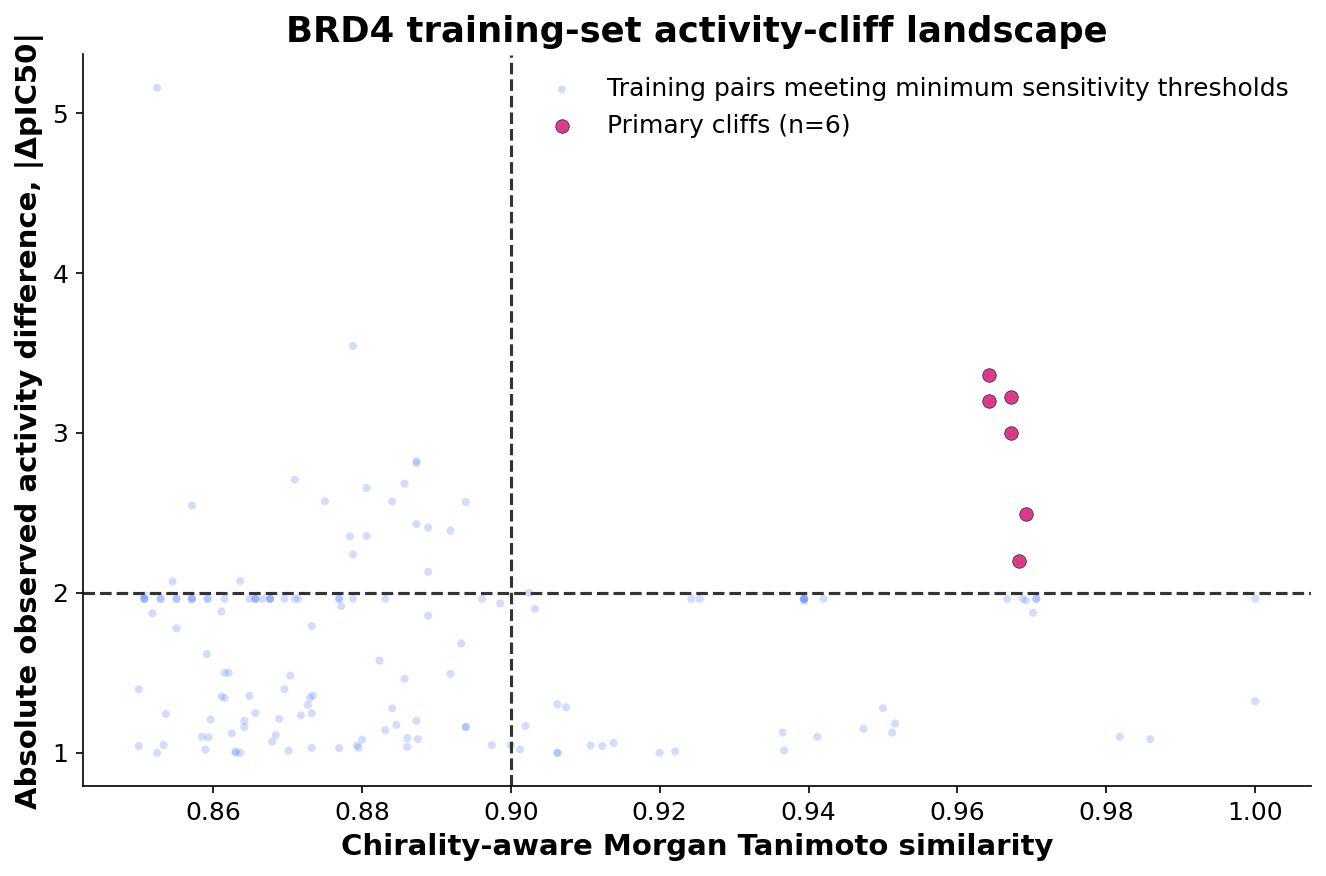

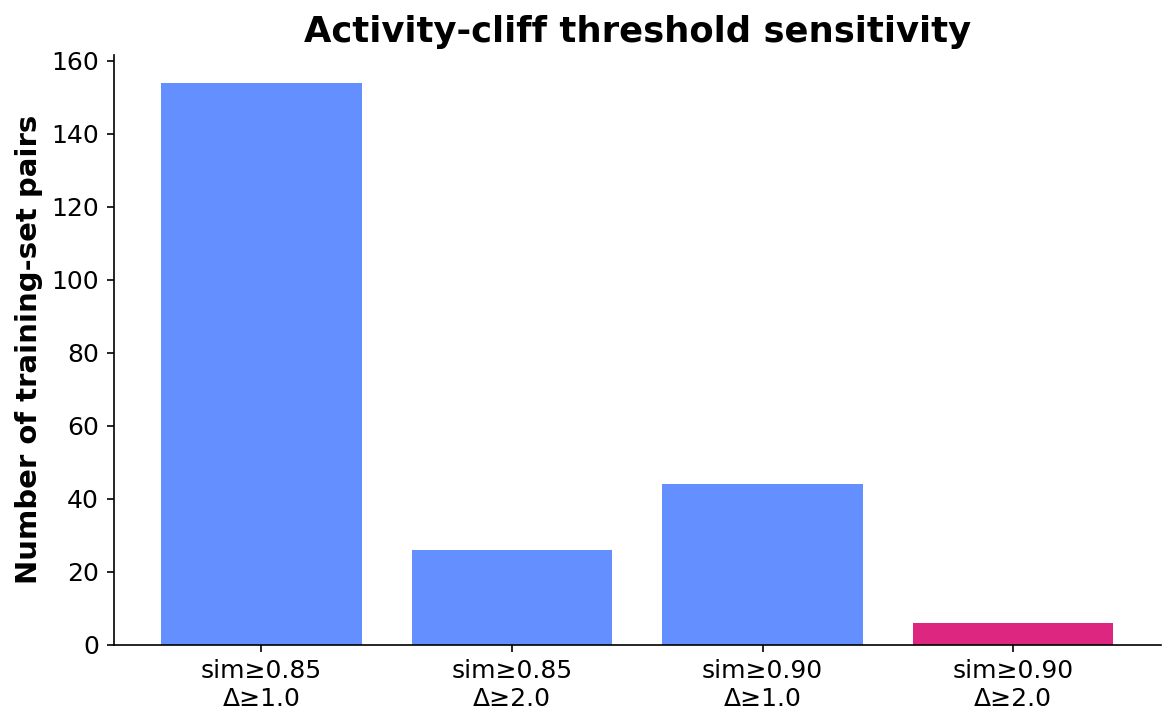

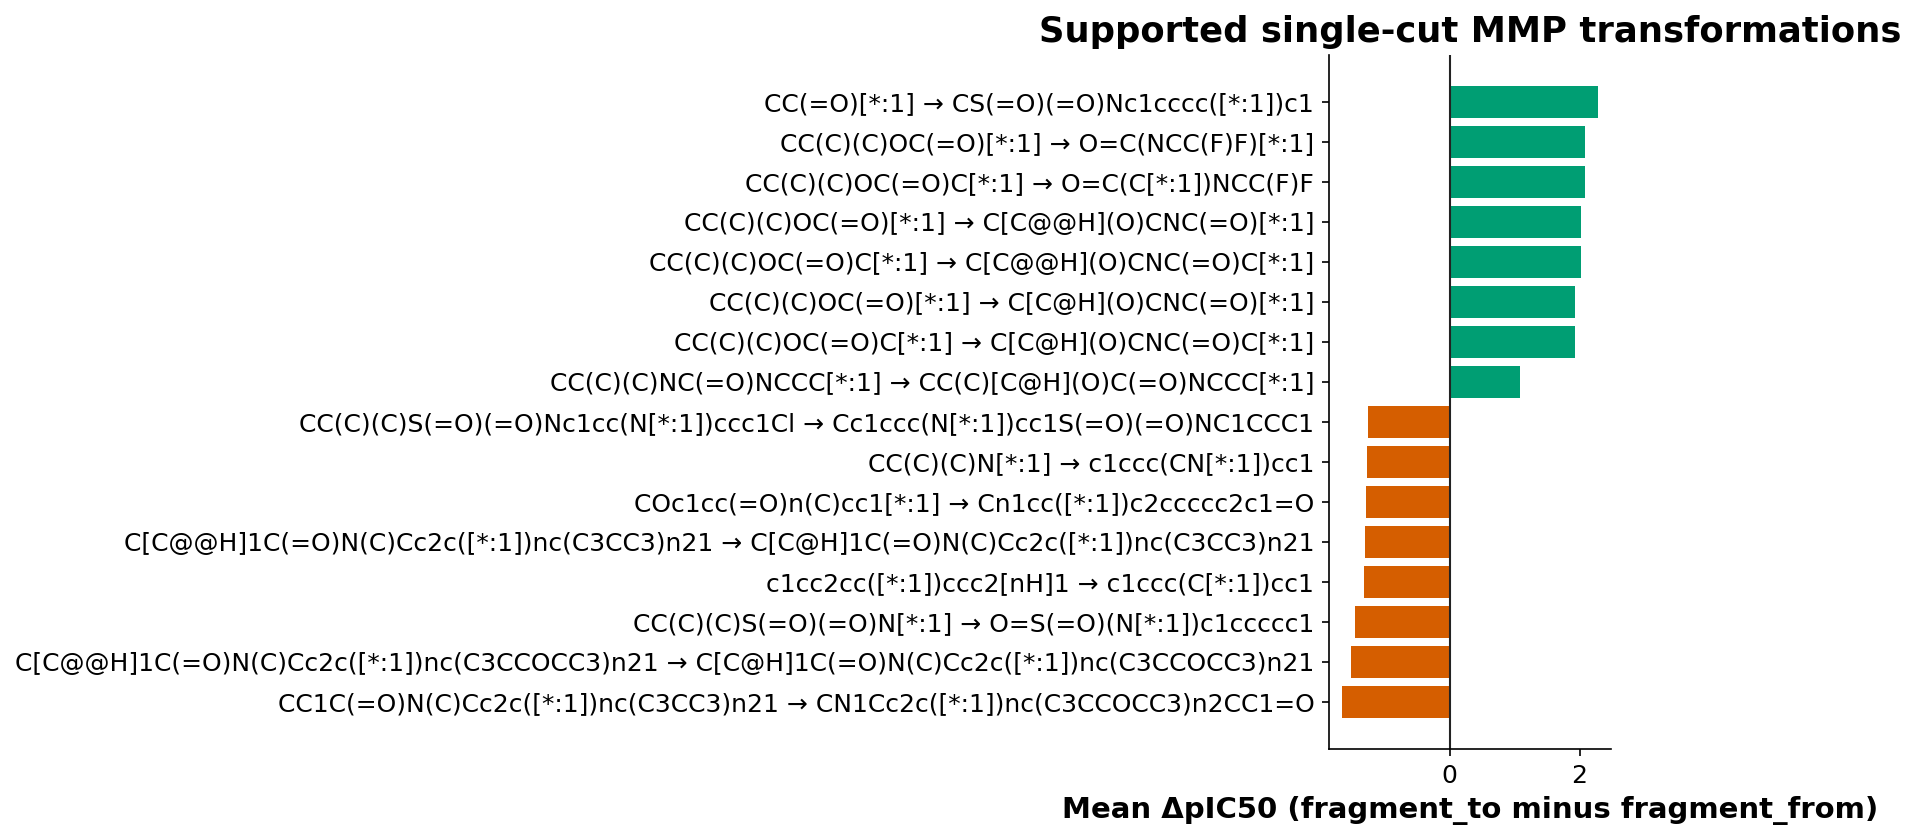

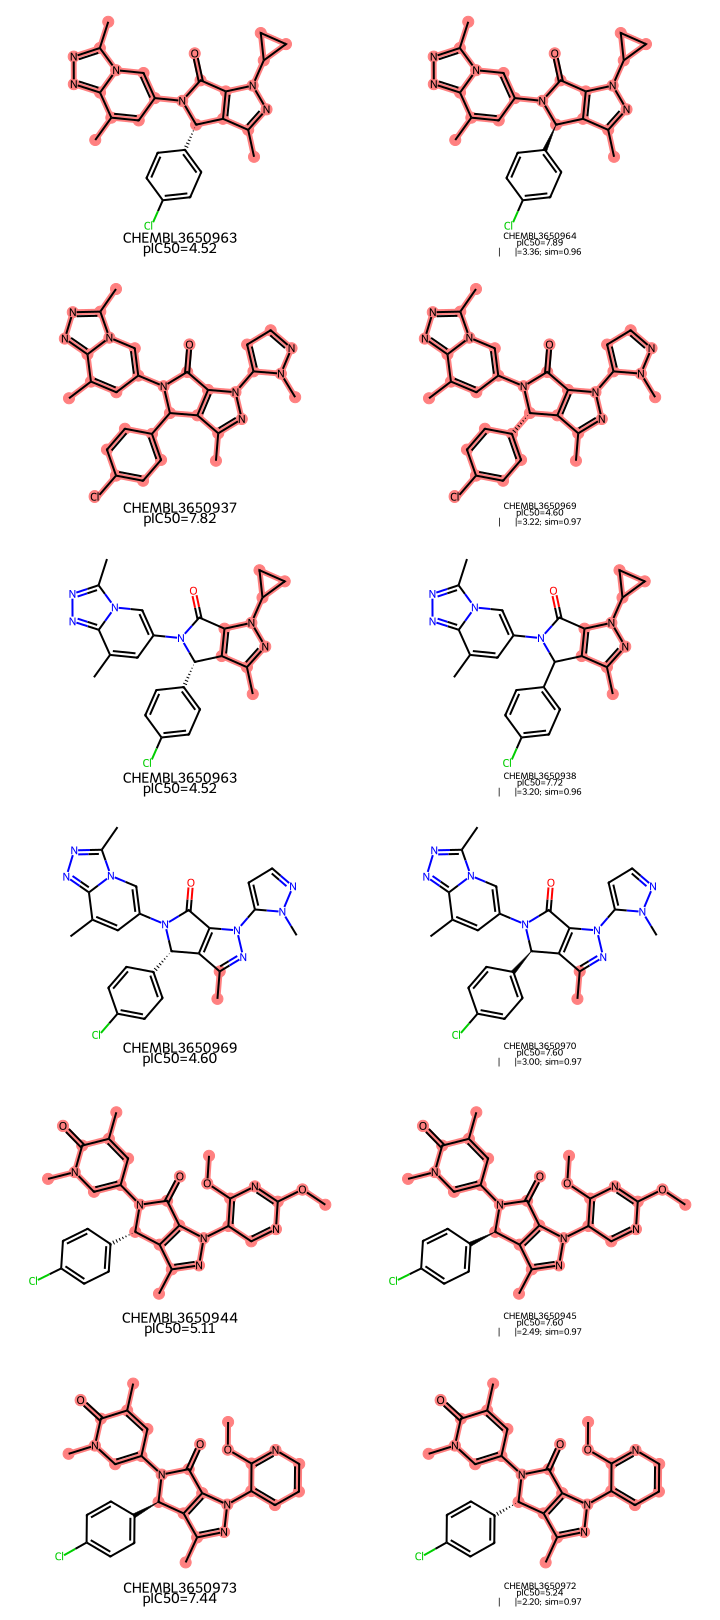

Displayed and saved 6 primary cliff structure pairs.
Figures saved under C:\Users\USER\Documents\E\Code\outputs\11_mmp_activity_cliffs\figures


In [23]:
# 8. Display and save the Stage 11 figures.
# Activity-cliff landscape among all pairs meeting the minimum declared thresholds.
plot_candidates = similar_pairs
if len(plot_candidates) > 50_000:
    plot_candidates = plot_candidates.sample(50_000, random_state=SEED)

fig, ax = plt.subplots(figsize=(9, 6))
if not plot_candidates.empty:
    ax.scatter(
        plot_candidates.tanimoto_chiral,
        plot_candidates.absolute_delta_pIC50,
        s=15, alpha=0.30, color="#648FFF", edgecolors="none",
        label="Training pairs meeting minimum sensitivity thresholds",
    )
if not primary_cliffs.empty:
    ax.scatter(
        primary_cliffs.tanimoto_chiral,
        primary_cliffs.absolute_delta_pIC50,
        s=42, alpha=0.9, color="#DC267F", edgecolors="black", linewidths=0.3,
        label=f"Primary cliffs (n={len(primary_cliffs)})",
    )
ax.axvline(PRIMARY_SIMILARITY, color="#333333", linestyle="--", linewidth=1.5)
ax.axhline(PRIMARY_ACTIVITY_GAP, color="#333333", linestyle="--", linewidth=1.5)
ax.set(
    xlabel="Chirality-aware Morgan Tanimoto similarity",
    ylabel="Absolute observed activity difference, |ΔpIC50|",
    title="BRD4 training-set activity-cliff landscape",
)
ax.legend(frameon=False, loc="best")
fig.tight_layout()

from src.utils import save_figure
save_figure(fig, FIGURE_DIR / "activity_cliff_landscape")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
plot_sens = cliff_sensitivity.copy()
plot_sens["label"] = plot_sens.apply(
    lambda r: f"sim≥{r.similarity_threshold_inclusive:.2f}\n"
              f"Δ≥{r.activity_gap_threshold_inclusive_pIC50:.1f}",
    axis=1,
)
colors = [
    "#DC267F"
    if (
        r.similarity_threshold_inclusive == PRIMARY_SIMILARITY
        and r.activity_gap_threshold_inclusive_pIC50 == PRIMARY_ACTIVITY_GAP
    )
    else "#648FFF"
    for r in plot_sens.itertuples(index=False)
]
ax.bar(plot_sens.label, plot_sens.n_activity_cliffs, color=colors)
ax.set(ylabel="Number of training-set pairs", title="Activity-cliff threshold sensitivity")
fig.tight_layout()
save_figure(fig, FIGURE_DIR / "activity_cliff_threshold_sensitivity")
display(fig)
plt.close(fig)

# Plot the most consistent supported transformations by mean observed ΔpIC50.
plot_transforms = pd.concat(
    [enriching.head(8), depleting.head(8)],
    ignore_index=True,
)
if not plot_transforms.empty:
    plot_transforms = plot_transforms.sort_values("mean_delta_pIC50", kind="stable")
    labels = [
        f"{a} → {b}"
        for a, b in zip(plot_transforms.fragment_from, plot_transforms.fragment_to)
    ]
    fig, ax = plt.subplots(figsize=(11, max(5, 0.36 * len(plot_transforms))))
    colors = [
        "#009E73" if value > 0 else "#D55E00"
        for value in plot_transforms.mean_delta_pIC50
    ]
    ax.barh(labels, plot_transforms.mean_delta_pIC50, color=colors)
    ax.axvline(0, color="#222222", linewidth=1)
    ax.set(
        xlabel="Mean ΔpIC50 (fragment_to minus fragment_from)",
        title="Supported single-cut MMP transformations",
    )
    fig.tight_layout()
    save_figure(fig, FIGURE_DIR / "mmp_supported_transformations")
    display(fig)
    plt.close(fig)
else:
    print("No transformations met the predeclared support rule for the summary figure.")

# Show the strongest primary cliffs as structure pairs; common MCS atoms are highlighted.
example_pairs = primary_cliffs.head(6)
if not example_pairs.empty:
    grid_mols, grid_legends, highlight_atoms = [], [], []

    for pair in example_pairs.itertuples(index=False):
        mol_a = Chem.MolFromSmiles(pair.smiles_a)
        mol_b = Chem.MolFromSmiles(pair.smiles_b)

        mcs = rdFMCS.FindMCS(
            [mol_a, mol_b],
            atomCompare=rdFMCS.AtomCompare.CompareElements,
            bondCompare=rdFMCS.BondCompare.CompareOrder,
            ringMatchesRingOnly=True,
            completeRingsOnly=True,
            matchChiralTag=True,
            timeout=3,
        )
        query = Chem.MolFromSmarts(mcs.smartsString) if mcs.numAtoms else None
        atoms_a = list(mol_a.GetSubstructMatch(query)) if query is not None else []
        atoms_b = list(mol_b.GetSubstructMatch(query)) if query is not None else []

        grid_mols.extend([mol_a, mol_b])
        highlight_atoms.extend([atoms_a, atoms_b])
        grid_legends.extend([
            f"{pair.chembl_id_a}\npIC50={pair.pIC50_a:.2f}",
            f"{pair.chembl_id_b}\npIC50={pair.pIC50_b:.2f}\n"
            f"|Δ|={pair.absolute_delta_pIC50:.2f}; sim={pair.tanimoto_chiral:.2f}",
        ])

    cliff_grid = Draw.MolsToGridImage(
        grid_mols,
        molsPerRow=2,
        subImgSize=(360, 270),
        legends=grid_legends,
        highlightAtomLists=highlight_atoms,
        useSVG=False,
    )

    # RDKit may return either a PIL image or an IPython Image.
    from io import BytesIO
    import base64
    from PIL import Image as PILImage

    cliff_grid_path = FIGURE_DIR / "primary_activity_cliff_structure_pairs.png"

    if hasattr(cliff_grid, "save"):
        cliff_grid.save(
            cliff_grid_path,
            format="PNG",
            dpi=(300, 300),
        )
    elif hasattr(cliff_grid, "data"):
        image_data = cliff_grid.data
        if isinstance(image_data, str):
            if image_data.startswith("data:image") and "," in image_data:
                image_data = image_data.split(",", 1)[1]
            image_data = base64.b64decode(image_data)

        with PILImage.open(BytesIO(image_data)) as pil_grid:
            pil_grid.save(
                cliff_grid_path,
                format="PNG",
                dpi=(300, 300),
            )
    else:
        raise TypeError(
            f"Unsupported RDKit grid image type: {type(cliff_grid)!r}"
        )

    display(cliff_grid)
    print(f"Displayed and saved {len(example_pairs)} primary cliff structure pairs.")
else:
    print("No primary activity cliffs met the declared thresholds; no structure grid was created.")

print(f"Figures saved under {FIGURE_DIR}")

In [24]:
# 9. Save a concise result summary, interpretation notes, and manifest.
summary = {
    "n_training_molecules": int(len(train)),
    "n_mmp_pairs": int(len(mmp_pairs)),
    "n_all_directed_transformations": int(len(transformations)),
    "n_supported_enriching_transformations": int(len(enriching)),
    "n_supported_depleting_transformations": int(len(depleting)),
    "n_primary_activity_cliffs": int(len(primary_cliffs)),
    "n_recorded_stereochemical_pairs": int(len(stereo_pairs)),
    "n_stereochemical_pairs_abs_delta_ge_2": int((stereo_pairs.absolute_delta_pIC50 >= 2.0).sum()) if len(stereo_pairs) else 0,
    "primary_cliff_similarity_threshold": PRIMARY_SIMILARITY,
    "primary_cliff_activity_gap_threshold_pIC50": PRIMARY_ACTIVITY_GAP,
    "test_activity_read": False,
    "models_refit": False,
    "feature_selection_performed": False,
}
summary_frame = pd.DataFrame([summary])
summary_frame.to_csv(TABLE_DIR / "stage11_summary.csv", index=False)
display(summary_frame)

interpretation_notes = f"""# Stage 11 interpretation notes

- Analysis used {len(train):,} training/development molecules only. Locked-test pIC50 labels were not read.
- Morgan fingerprints were regenerated with radius {FP_RADIUS}, {FP_SIZE} bits, chirality={USE_CHIRALITY}; every bit vector matched the Stage 03 raw ECFP4 table exactly.
- Primary activity cliffs required chiral Morgan Tanimoto ≥{PRIMARY_SIMILARITY:.2f} and |ΔpIC50| ≥{PRIMARY_ACTIVITY_GAP:.1f}. Threshold sensitivity is in `activity_cliff_threshold_sensitivity.csv`.
- MMP analysis splits the dot-disconnected fragments returned by one-cut RDKit MMPA records, tests both core/sidechain orientations, and saves per-molecule diagnostics. If no exact pairs are present, cliff/stereo analyses continue. MMP directions use a deterministic lexical fragment order. A positive mean ΔpIC50 means fragment_from → fragment_to was associated with increased potency. Supported transformations require at least {MMP_MIN_PAIRS} pairs and ≥{MMP_MIN_DIRECTION_CONSISTENCY:.0%} directional consistency; depleting rules require consistent negative deltas.
- The OOF pair table reports same-fold and cross-fold comparisons separately. Same-fold pairs were held out together by the same CV model; cross-fold pairs were not jointly held out by one model and are weaker evidence.
- Pairs share compounds and chemical series, so pair counts are not independent observations. MMP/cliff associations are descriptive and can reflect assay heterogeneity, activity rounding/censoring, or curation effects.
- Stereochemical pairs represent different recorded isomeric structures with the same stereo-removed canonical connectivity. Database records alone do not establish experimental confirmation or assay comparability of the stereoisomers.
- No models were refitted, no features were selected, and no candidate molecules were generated. Candidate prioritization is Stage 12.
"""
(STAGE_DIR / "INTERPRETATION_NOTES.md").write_text(interpretation_notes, encoding="utf-8")

outputs = sorted(
    path for path in STAGE_DIR.rglob("*")
    if path.is_file() and path.name != "manifest.json"
)
write_manifest(
    "11_mmp_activity_cliffs",
    {
        "data_partition": "Stage 04 training/development only",
        "primary_cliff": {"similarity": ">=0.90", "absolute_delta_pIC50": ">=2.0"},
        "sensitivity_similarity_thresholds": list(SIMILARITY_THRESHOLDS),
        "sensitivity_activity_gap_thresholds": list(ACTIVITY_GAP_THRESHOLDS),
        "fingerprint": {"radius": FP_RADIUS, "bits": FP_SIZE, "include_chirality": USE_CHIRALITY,
                        "verified_exactly_against_stage03": True},
        "mmp_fragmentation": {"method": "RDKit single-cut; larger heavy-atom fragment is core",
                              "max_cuttable_bonds_per_molecule": 30},
        "mmp_rule_support": {"minimum_pairs": MMP_MIN_PAIRS,
                              "minimum_direction_consistency": MMP_MIN_DIRECTION_CONSISTENCY,
                              "depleting_consistency_checked_in_negative_direction": True},
        "oof_source": "Stage 08 fresh five-fold scaffold-grouped training OOF predictions",
        "models_refit": False,
        "test_activity_read": False,
        "candidate_generation": False,
    },
    inputs=[CLEANED_FILE, TRAIN_IDS_FILE, TEST_IDS_FILE, OOF_FILE, FP_FILE],
    outputs=outputs,
)
print(f"Stage 11 complete. Tables and figures are in {STAGE_DIR}.")



,n_training_molecules,n_mmp_pairs,n_all_directed_transformations,n_supported_enriching_transformations,n_supported_depleting_transformations,n_primary_activity_cliffs,n_recorded_stereochemical_pairs,n_stereochemical_pairs_abs_delta_ge_2,primary_cliff_similarity_threshold,primary_cliff_activity_gap_threshold_pIC50,test_activity_read,models_refit,feature_selection_performed
0,5134,91965,71995,1236,1015,6,405,23,0.9,2.0,False,False,False


Stage 11 complete. Tables and figures are in C:\Users\USER\Documents\E\Code\outputs\11_mmp_activity_cliffs.


## Reading the outputs

- `mmp_fragmentation_diagnostics.csv` reports eligible cuts, unpacked MMPA records, split components, and per-molecule status. `mmp_pairs_training.csv` lists matched pairs, shared cores, fragments, training pIC50 values, and directed activity differences. If no exact single-cut pairs are present, the notebook reports why and continues to the cliff and stereochemistry analyses.
- `mmp_transformation_summary_all.csv` includes supported and unsupported transformations. The enriching/depleting tables apply the declared minimum pair count and direction-consistency rule.
- `activity_cliff_threshold_sensitivity.csv` reports all four cutoff combinations, unique cliff-pair counts, molecule counts, and same-/cross-fold counts.
- `primary_activity_cliffs_training.csv` lists the primary cliffs with training molecule IDs, structures, activities, and chiral similarity.
- `recorded_stereochemical_pairs_training.csv` examines same-connectivity stereochemical variants independently of the cliff similarity cutoff.
- `oof_pair_difference_metrics.csv` compares pair activity differences with saved Stage 08 OOF predictions, with same-fold and cross-fold pairs separated.

The older supplied MMP/cliff counts used a different dataset split and different cliff cutoffs. Use the new Stage 11 outputs for the current scaffold-split analysis. Stage 12 is the next place to consider candidate structures, using only supported transformations and keeping locked-test data out of candidate selection.
